# **VAE Complex 1: autoencoder variacional derivado de `AE_complex2_VGG`**

## **0. Introducción y objetivo**

Este notebook **parte del último autoencoder de la serie, `AE_complex2_VGG`**. Allí cerramos los autoencoders deterministas con un FID de reconstrucción de `61.17` (latente de `256`, pérdida `L1 + (1 - SSIM)` más pérdida perceptual VGG) y con un problema de fondo que ninguna mejora anterior abordaba (sección 10.2 de ese notebook): **el decoder solo ve los latentes que produce el encoder con las imágenes de `train`**. Esos puntos ocupan una región pequeña y desigual del espacio, con grandes zonas vacías, y en el morphing el decoder recibe mezclas $z_\alpha = (1-\alpha) z_A + \alpha z_B$ que puede que nunca haya visto. Como mejora futura propusimos un **autoencoder variacional (VAE)**, y este notebook lo prueba **sobre la base del último AE** para ver qué tal lo hace.

Un **VAE** cambia el encoder: en lugar de producir un único vector $z$, produce una **distribución** $q_\phi(z \mid x) = \mathcal{N}(\mu(x), \sigma^2(x))$. Se muestrea un $z$ de esa distribución, el decoder lo reconstruye, y el entrenamiento añade a la pérdida de reconstrucción una **divergencia KL** que empuja cada distribución hacia una gaussiana estándar $p(z) = \mathcal{N}(0, I)$. Así, el espacio latente se llena de forma densa y regular alrededor del origen, y la interpolación entre dos latentes (y el muestreo de latentes nuevos) cae en zonas que el decoder sí ha visto durante el entrenamiento.

Se trata de una variante controlada de `AE_complex2_VGG`: usamos las mismas imágenes RGB de `64x64`, la misma arquitectura convolucional, el mismo latente de `256` dimensiones, la misma pérdida de reconstrucción (`L1 + (1 - SSIM)` + VGG con `λ = 1e-4`), la misma semilla, el mismo Cosine Decay y `30` épocas. **Las diferencias son las propias del VAE**: el encoder devuelve media y log-varianza, se muestrea con el truco de reparametrización y se añade el término KL. Por eso la comparación directa es con `AE_complex2_VGG` (FID `61.17`).

**Qué dejamos fuera.** La otra mejora propuesta en `AE_complex2_VGG`, un autoencoder mayor con latente de `512` dimensiones y entrada en escala de grises, se queda **como código en la sección 11 de aquel notebook**. Si tras ver el VAE creemos que merece la pena, lo probaremos más adelante.

Igual que en los notebooks anteriores, trabajamos de forma **determinista en la medida permitida por el entorno**: fijamos las semillas, usamos las particiones guardadas y seleccionamos siempre los mismos ejemplos. `TRAIN_MODEL` está a `True` porque este modelo aún no tiene checkpoints en `autoencoders/checkpoints/`; **tras el primer entrenamiento hay que cambiarlo a `False`** para poder reproducir las visualizaciones y métricas cargando los modelos y el historial ya calculados.

El recorrido será: cargar los datos, definir el VAE, justificar la pérdida, entrenar o cargar el modelo, evaluar reconstrucciones en `test`, diagnosticar el espacio latente, medir la calidad con FID (reconstrucción y generación desde el prior) y terminar generando secuencias de morphing con interpolación lineal y esférica.

---

## **1. Configuración e imports**

Importamos las bibliotecas de visualización, tratamiento de imágenes, TensorFlow y TorchMetrics. Las rutas se resuelven desde `autoencoders/`, donde está este notebook. Conservamos `attrs.npy` para análisis posteriores (por ejemplo, direcciones semánticas), aunque el entrenamiento utiliza `x.npy` e `ids.npy`.

Los parámetros son los de `AE_complex2_VGG` (`LATENT_DIM = 256`, `EPOCHS = 30`, `BATCH_SIZE = 128`) más `BETA = 1.0`, el peso del término KL (se explica en la sección 4). A diferencia de los notebooks anteriores, el modelo no es un único `.keras` de autoencoder: guardamos el **encoder** (que devuelve media, log-varianza y el latente muestreado), el **decoder** y el historial. Los checkpoints usan el nombre `vae_complex1_latent256`.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import torch
from torchmetrics.image.fid import FrechetInceptionDistance

from PIL import Image
from IPython.display import Image as IPyImage, display

I0000 00:00:1793905013.602126   28543 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793905014.007972   28543 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793905015.698113   28543 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
SEED = 1234
IMG_SIZE = 64
CHANNELS = 3
LATENT_DIM = 256
BATCH_SIZE = 128
EPOCHS = 30
# Peso del término KL. Está normalizado por el número de valores de la imagen (ver sección 4).
BETA = 1.0

# Este modelo aún no tiene checkpoints: la primera ejecución entrena. Después, cambiar a False.
TRAIN_MODEL = False
NOTEBOOK_NAME = "vae_complex1_latent256"

PROCESSED_DIR = Path("../data/processed")

# Verificar que están los 9 archivos requeridos
_required_data_files = tuple(
    Path(split) / filename
    for split in ("train", "val", "test")
    for filename in ("x.npy", "attrs.npy", "ids.npy")
)
if not all((PROCESSED_DIR / relative_path).is_file() for relative_path in _required_data_files):
    raise FileNotFoundError(f"Faltan algunos archivos en {PROCESSED_DIR.resolve()}")

CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

ENCODER_PATH = CHECKPOINT_DIR / f"encoder_{NOTEBOOK_NAME}.keras"
DECODER_PATH = CHECKPOINT_DIR / f"decoder_{NOTEBOOK_NAME}.keras"
HISTORY_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}_history.json"

np.random.seed(SEED)
tf.random.set_seed(SEED)
print(f"Datos localizados correctamente en: {PROCESSED_DIR.resolve()}")

Datos localizados correctamente en: /home/sanru/Escritorio/7_cuatri/PCD/project/morphing/data/processed


In [3]:
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    # Por defecto TensorFlow reserva casi toda la VRAM. Pedimos memoria solo según la necesite para dejar
    # espacio a PyTorch, que calcula el FID (TorchMetrics) en la misma GPU. Debe ejecutarse antes de usarla.
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as error:
        print(f"No se pudo activar el crecimiento de memoria (reinicia el kernel): {error}")
    print(f"GPU detectada: {gpus}")
else:
    print("Corriendo en CPU.")

GPU detectada: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---

## **2. Carga de `train`, `val` y `test`**

No volvemos a crear un *split*: respetamos exactamente las particiones guardadas en `data/processed`, de modo que la comparación con la serie anterior sea justa. Convertimos las imágenes de `uint8 [0, 255]` a `float32 [0, 1]`, porque la salida del decoder usa una sigmoide. Igual que un autoencoder, el VAE aprende a reconstruir su entrada, por lo que la entrada y el objetivo de cada ejemplo son la misma imagen.

In [4]:
def load_split(name):
    split_dir = PROCESSED_DIR / name
    x = np.load(split_dir / "x.npy", allow_pickle=False)
    attrs = np.load(split_dir / "attrs.npy", allow_pickle=False)
    ids = np.load(split_dir / "ids.npy", allow_pickle=True)
    if x.ndim != 4 or x.shape[1:] != (IMG_SIZE, IMG_SIZE, CHANNELS):
        raise ValueError(f"{name}/x.npy tiene forma {x.shape}; se esperaba (N, 64, 64, 3)")
    if attrs.shape[0] != x.shape[0] or ids.shape[0] != x.shape[0]:
        raise ValueError(f"Los archivos de {name} no tienen el mismo número de ejemplos")
    return x.astype("float32") / 255.0, attrs, ids

x_train, attrs_train, ids_train = load_split("train")
x_val, attrs_val, ids_val = load_split("val")
x_test, attrs_test, ids_test = load_split("test")

print(f"train: {x_train.shape}, val: {x_val.shape}, test: {x_test.shape}")
print(f"Rango train: [{x_train.min():.3f}, {x_train.max():.3f}]")

train: (60000, 64, 64, 3), val: (5000, 64, 64, 3), test: (10000, 64, 64, 3)
Rango train: [0.000, 1.000]


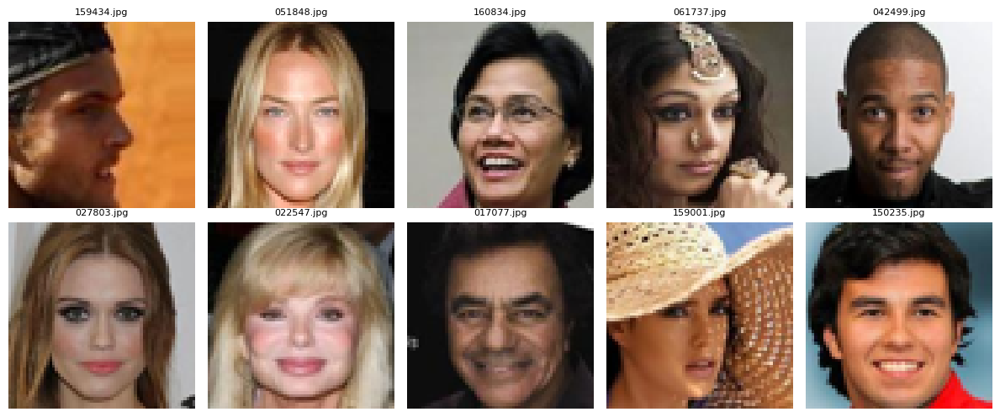

In [5]:
def show_images(images, titles=None, cols=5, figsize=(12, 8)):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax, image, index in zip(axes.flat, images, range(len(images))):
        ax.imshow(np.clip(image, 0, 1))
        ax.axis("off")
        if titles is not None:
            ax.set_title(str(titles[index]), fontsize=8)
    for ax in axes.flat[len(images):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

sample_rng = np.random.default_rng(SEED)
sample_indices = sample_rng.choice(len(x_train), size=10, replace=False)
show_images(x_train[sample_indices], ids_train[sample_indices], cols=5, figsize=(12, 5))

---

## **3. Encoder, decoder y VAE**

Mantenemos la arquitectura de `AE_complex2_VGG` (la de `AE_complex1_latent`, sin bloques residuales) y cambiamos solo lo imprescindible para convertirla en un VAE:

- **Encoder:** las mismas cuatro convoluciones `4x4` con `stride=2` (`32, 64, 128, 256` filtros) seguidas de `BatchNormalization` y `LeakyReLU`. La capa densa final se sustituye por **dos cabezas** de `256` unidades, `z_mean` ($\mu$) y `z_log_var` ($\log\sigma^2$). Predecimos el logaritmo de la varianza y no la desviación típica porque no tiene restricciones de signo y es más estable numéricamente.
- **Muestreo con reparametrización:** $z = \mu + \sigma \odot \varepsilon$, con $\varepsilon \sim \mathcal{N}(0, I)$. Escribir el muestreo así deja el ruido como una entrada externa y permite que el gradiente fluya hasta $\mu$ y $\sigma$.
- **Decoder:** idéntico al de `AE_complex2_VGG` (capa densa a `4x4x256`, sobremuestreo bilineal y convoluciones, sigmoide final).
- **Sin regularizador `L2` en el latente:** en los autoencoders usábamos `l2(1e-5)` para acotar el latente. Aquí esa función la cumple el término KL.

El encoder devuelve las tres salidas `[z_mean, z_log_var, z]`. Para el morphing y para evaluar las reconstrucciones usamos **siempre `z_mean`**, es decir, la reconstrucción determinista, sin ruido. El ruido solo se usa durante el entrenamiento.

El modelo `VAE` es un `keras.Model` con un `train_step` propio, porque la pérdida depende de tres salidas del encoder y no encaja en el esquema `compile(loss=...)` de los notebooks anteriores. Para poder reutilizar el resto del código de la serie, definimos además un modelo determinista `autoencoder` que compone `z_mean` con el decoder.

In [6]:
@keras.utils.register_keras_serializable(package="vae")
class Sampling(layers.Layer):
    """Truco de reparametrización: z = mu + sigma * epsilon."""

    def __init__(self, seed=SEED, **kwargs):
        super().__init__(**kwargs)
        self.seed = seed
        self.seed_generator = keras.random.SeedGenerator(seed)

    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = keras.random.normal(keras.ops.shape(z_mean), seed=self.seed_generator)
        return z_mean + keras.ops.exp(0.5 * z_log_var) * epsilon

    def get_config(self):
        config = super().get_config()
        config.update({"seed": self.seed})
        return config

    def compute_output_shape(self, input_shape):
        return input_shape[0]


encoder_inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS), name="encoder_input")
x = encoder_inputs
for filters in (32, 64, 128, 256):
    x = layers.Conv2D(filters, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)
x = layers.Flatten()(x)
z_mean = layers.Dense(LATENT_DIM, name="z_mean")(x)
z_log_var = layers.Dense(LATENT_DIM, name="z_log_var")(x)
z = Sampling(name="z")([z_mean, z_log_var])
encoder_vae = keras.Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder_vae")
encoder_vae.summary()

I0000 00:00:1793905027.195999   28543 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2142 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Model: "encoder_vae"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 32, 32,    │      1,536 │ encoder_input[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 32, 32,    │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu         │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 16, 16,    │     32,768 │ leaky_re_lu[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_1       │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 8, 8, 128) │    131,072 │ leaky_re_lu_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 8, 128) │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_2       │ (None, 8, 8, 128) │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 4, 4, 256) │    524,288 │ leaky_re_lu_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 4, 4, 256) │      1,024 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_3       │ (None, 4, 4, 256) │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 4096)      │          0 │ leaky_re_lu_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 256)       │  1,048,832 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 256)       │  1,048,832 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z (Sampling)        │ (None, 256)       │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,789,248 (10.64 MB)

 Trainable params: 2,788,288 (10.64 MB)

 Non-trainable params: 960 (3.75 KB)

In [7]:
decoder_inputs = keras.Input(shape=(LATENT_DIM,), name="decoder_input")
x = layers.Dense(4 * 4 * 256, use_bias=False)(decoder_inputs)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)
x = layers.Reshape((4, 4, 256))(x)

for filters in (256, 128, 64, 32):
    x = layers.UpSampling2D(size=(2, 2), interpolation="bilinear")(x)
    x = layers.Conv2D(filters, kernel_size=3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

decoder_outputs = layers.Conv2D(
    CHANNELS, kernel_size=3, padding="same", activation="sigmoid", name="decoder_output"
)(x)
decoder_vae = keras.Model(decoder_inputs, decoder_outputs, name="decoder_vae")
decoder_vae.summary()

Model: "decoder_vae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4096)           │     1,048,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 4096)           │        16,384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 256)      │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 64)     │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_3 (UpSampling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 64, 64, 32)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output (Conv2D)         │ (None, 64, 64, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 2,044,643 (7.80 MB)

 Trainable params: 2,035,491 (7.76 MB)

 Non-trainable params: 9,152 (35.75 KB)

---

## **4. Función de pérdida (ELBO) y optimización**

El VAE maximiza una cota inferior de la verosimilitud (ELBO), que se expresa como una pérdida con dos términos:

$$\mathcal{L} = \underbrace{\mathcal{L}_{recon}(x, \hat{x})}_{\text{reconstrucción}} + \beta \cdot \underbrace{D_{KL}\big(q_\phi(z \mid x)\,\|\,\mathcal{N}(0, I)\big)}_{\text{regularización}}, \qquad D_{KL} = -\tfrac{1}{2} \sum_{j=1}^{256} \left(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\right)$$

- **Reconstrucción:** mantenemos la pérdida de `AE_complex2_VGG`, $\mathcal{L}_{recon} = 0.5\,L_1 + 0.5\,(1 - SSIM) + \lambda\, L_{VGG}$ con $\lambda = 10^{-4}$ y $L_{VGG}$ la diferencia $L_1$ entre las activaciones de `block1_conv2` y `block2_conv2` de una VGG16 congelada, de modo que la única diferencia con ese notebook en el objetivo es el término KL. Con una verosimilitud gaussiana este término sería un MSE; no lo usamos por las razones que ya vimos en la sección 4 de `AE_complex1` (tiende a emborronar). Esto significa que la pérdida no es estrictamente un ELBO, y que `β` no tiene una interpretación probabilística exacta.
- **Divergencia KL:** penaliza que la distribución de cada imagen se aleje de $\mathcal{N}(0, I)$. Con $\beta = 0$ recuperaríamos un autoencoder con ruido; con $\beta$ muy grande el encoder ignoraría la imagen (*posterior collapse*) y todas las reconstrucciones serían iguales.

**Escala de `β`.** La reconstrucción es una media por píxel (valores de orden `0.1`), mientras que la KL es una suma sobre `256` dimensiones (puede valer cientos de nats). Para que `β = 1` sea un punto de partida razonable, dividimos la KL por el número de valores de la imagen, `64·64·3 = 12288`:

$$\mathcal{L} = \mathcal{L}_{recon} + \beta \cdot \frac{D_{KL}}{12288}$$

Es una normalización en la línea de la `β` normalizada de β-VAE, que hace que `β` sea menos dependiente del tamaño de la imagen. **No hemos ajustado este valor**: es el principal hiperparámetro del modelo y el primer experimento a hacer (por ejemplo `β ∈ {0.5, 1, 2}`, como se plantea en el experimento C del README). Un `β` pequeño reconstruye mejor pero regulariza menos el latente; uno grande regulariza más a costa de reconstrucciones más borrosas.

Mantenemos `Cosine Decay` de `1e-3` a `1e-5` a lo largo de las `30` épocas y `EarlyStopping`. Como la pérdida total incluye el término KL, `loss` y `val_loss` **no son comparables** con los de los autoencoders. `recon_loss` sí lo es con la `val_loss` de `AE_complex2_VGG` (`0.1262`), porque usa la misma pérdida de reconstrucción. Para comparar la calidad usamos el FID, y registramos por separado `recon_loss` y `kl_loss`.

In [8]:
def ssim_l1_loss(y_true, y_pred):
    l1 = tf.reduce_mean(tf.abs(y_true - y_pred))
    structural_loss = 1.0 - tf.reduce_mean(tf.image.ssim(y_true, y_pred, max_val=1.0))
    return 0.5 * l1 + 0.5 * structural_loss

LAMBDA = 1e-4
vgg = keras.applications.VGG16(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
)
vgg.trainable = False
LAYERS = ["block1_conv2", "block2_conv2"]
feat = keras.Model(vgg.input, [vgg.get_layer(name).output for name in LAYERS], name="vgg_features")
feat.trainable = False


def perceptual(y_true, y_pred):
    preprocess = lambda x: keras.applications.vgg16.preprocess_input(x * 255.0)
    true_features = feat(preprocess(y_true), training=False)
    pred_features = feat(preprocess(y_pred), training=False)
    return tf.add_n([
        tf.reduce_mean(tf.abs(true - pred))
        for true, pred in zip(true_features, pred_features)
    ])


def full_loss(y_true, y_pred):
    # Pérdida de reconstrucción de AE_complex2_VGG.
    return ssim_l1_loss(y_true, y_pred) + LAMBDA * perceptual(y_true, y_pred)


INPUT_DIM = IMG_SIZE * IMG_SIZE * CHANNELS


class VAE(keras.Model):
    def __init__(self, encoder, decoder, beta=1.0, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.beta = beta
        self.loss_tracker = keras.metrics.Mean(name="loss")
        self.recon_tracker = keras.metrics.Mean(name="recon_loss")
        self.kl_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.loss_tracker, self.recon_tracker, self.kl_tracker]

    def call(self, inputs):
        # Reconstrucción determinista (sin ruido), a través de z_mean.
        return self.decoder(self.encoder(inputs)[0])

    def compute_losses(self, x, training):
        z_mean, z_log_var, z = self.encoder(x, training=training)
        reconstruction = self.decoder(z, training=training)
        recon_loss = full_loss(x, reconstruction)
        # KL por imagen (suma sobre las dimensiones latentes) y media sobre el lote.
        kl_loss = tf.reduce_mean(
            -0.5 * tf.reduce_sum(1.0 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=-1)
        )
        total_loss = recon_loss + self.beta * kl_loss / INPUT_DIM
        return total_loss, recon_loss, kl_loss

    def _update_metrics(self, total_loss, recon_loss, kl_loss):
        self.loss_tracker.update_state(total_loss)
        self.recon_tracker.update_state(recon_loss)
        self.kl_tracker.update_state(kl_loss)
        return {metric.name: metric.result() for metric in self.metrics}

    def train_step(self, data):
        x = data[0] if isinstance(data, (tuple, list)) else data
        with tf.GradientTape() as tape:
            total_loss, recon_loss, kl_loss = self.compute_losses(x, training=True)
        gradients = tape.gradient(total_loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(gradients, self.trainable_variables))
        return self._update_metrics(total_loss, recon_loss, kl_loss)

    def test_step(self, data):
        x = data[0] if isinstance(data, (tuple, list)) else data
        total_loss, recon_loss, kl_loss = self.compute_losses(x, training=False)
        return self._update_metrics(total_loss, recon_loss, kl_loss)


vae = VAE(encoder_vae, decoder_vae, beta=BETA, name="vae")

INITIAL_LEARNING_RATE = 1e-3
MIN_LEARNING_RATE = 1e-5
DECAY_STEPS = int(np.ceil(len(x_train) / BATCH_SIZE) * EPOCHS)
learning_rate_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=INITIAL_LEARNING_RATE,
    decay_steps=DECAY_STEPS,
    alpha=MIN_LEARNING_RATE / INITIAL_LEARNING_RATE,
)

vae.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate_schedule))
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
]

# Modelo determinista (imagen -> z_mean -> imagen) que comparte pesos con el VAE.
# Nos permite reutilizar el código de evaluación del resto de la serie.
autoencoder_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS), name="autoencoder_input")
autoencoder = keras.Model(
    autoencoder_input,
    decoder_vae(encoder_vae(autoencoder_input)[0]),
    name="autoencoder",
)

---

## **5. Entrenamiento y guardado**

Con `TRAIN_MODEL = True` entrenamos usando únicamente `train` y validamos con `val` durante un máximo de `30` épocas; `test` queda reservado para la evaluación final. Guardamos el encoder, el decoder y el historial (con `loss`, `recon_loss` y `kl_loss`) para poder reproducir el resto del notebook sin volver a entrenar. Con `TRAIN_MODEL = False` cargamos esos artefactos ya calculados y reconstruimos el modelo `VAE` a partir de ellos.

**Resultados del entrenamiento.** La mejor época según `val_loss` es la **`30`**, es decir, la última: el entrenamiento no se detuvo por `EarlyStopping` y llegó hasta el final del Cosine Decay. Los valores finales son:

| | `loss` (total) | `recon_loss` | `kl_loss` (nats por imagen) |
| --- | --- | --- | --- |
| `train` | `0.1624` | `0.1338` | `351.2` |
| `val` | `0.1623` | `0.1338` | `350.2` |

La pérdida seguía bajando al terminar, pero muy despacio: `val_loss` mejora solo `0.0014` entre las épocas `25` y `30`. Una parte de ese aplanamiento se debe a que el Cosine Decay deja la tasa de aprendizaje en `1e-5` al final, así que no podemos saber cuánto más se ganaría con más épocas. La **KL no se ha colapsado**: sube de `≈ 235` nats en la primera época a `≈ 350` y se estabiliza, lo que indica que el encoder usa la información de cada imagen y que no hay *posterior collapse*.

### **Nota técnica: por qué entregamos los datos por lotes (`BatchSequence`)**

En los notebooks anteriores entrenamos con `autoencoder.fit(x_train, x_train, batch_size=...)`. **Aquí no lo hacemos así**, y conviene entender por qué porque la diferencia no afecta al modelo, solo a la memoria.

**El problema.** Al entrenar en una GPU de `4 GB` (RTX 3050 de portátil) el entrenamiento fallaba antes de empezar la primera época con:

```
InternalError: Failed copying input tensor from .../device:CPU:0 to .../device:GPU:0
in order to run _EagerConst: Dst tensor is not initialized.
```

Ese mensaje es, en la práctica, un *out of memory* de la GPU. No es un fallo de la arquitectura ni de la pérdida.

**La causa.** Cuando se le pasa a `fit` un array de NumPy, Keras lo incorpora **entero** como una constante de su canal de datos (`tf.data`), y si hay GPU esa constante se copia a la memoria de la GPU de una sola vez. Nuestro `x_train` ocupa `60000 × 64 × 64 × 3 × 4 bytes ≈ 2.95 GB` en `float32`. Sumado a lo que ya ocupan el modelo, la VGG16 y las activaciones, no cabe en `4 GB`. Aunque la GPU estuviera vacía, iría al límite. En una GPU con más memoria el problema no aparecería; es de esperar que por eso los notebooks anteriores no lo necesiten, aunque no hemos comprobado con qué GPU se entrenaron.

**La solución.** Una clase `BatchSequence` (un `keras.utils.PyDataset`) que **mantiene las imágenes en la RAM del ordenador** y entrega a Keras un lote de `128` imágenes cada vez. A la GPU solo llega un lote (`128 × 64 × 64 × 3 × 4 bytes ≈ 6 MB`) en cada paso, en lugar de las `60000` imágenes a la vez. Se usa igual para `val`.

**Qué cambia y qué no:**

- **No cambia** el modelo, la pérdida, el optimizador, el `Cosine Decay`, el tamaño de lote ni las épocas. Cada paso de entrenamiento procesa un lote de `128` imágenes, como antes.
- **Barajado:** `fit(x_train)` baraja las imágenes en cada época. `BatchSequence(shuffle=True)` hace lo mismo (baraja al crearse y al final de cada época) con un generador de números aleatorios con semilla fija (`SEED`), de modo que el orden es reproducible. Esto es importante porque `train` está ordenado por identificador de imagen: sin barajar, la primera época vería las imágenes en el orden del fichero. **No será exactamente el mismo orden** que con `fit(x_train)`, así que los resultados no serán idénticos bit a bit a los de un entrenamiento hecho con la otra forma, aunque estadísticamente son equivalentes.
- **Coste:** hay un pequeño trabajo extra de CPU para preparar cada lote (seleccionar `128` imágenes del array). No lo hemos medido, pero cabe esperar que sea pequeño frente al tiempo de cálculo en la GPU.

**Cuándo hace falta.** Solo si el conjunto de entrenamiento no cabe cómodamente en la memoria de la GPU. No hay que cambiar los notebooks anteriores: funcionan bien con su `fit(x_train, x_train)` en una GPU con memoria suficiente. En `float32` y RGB, el conjunto de `train` es el elemento más grande en memoria; en escala de grises (un canal) ocuparía un tercio.

**Alternativas que no hemos usado (y no hemos probado):** convertir `x_train` a `float16` (cambia la precisión de los datos de entrada) o mantenerlo en `uint8` y normalizar dentro del modelo (cambia la estructura del modelo respecto a la serie). Reducir el `BATCH_SIZE` no resolvería este error en concreto, porque lo que se copia a la GPU es el conjunto entero y no un lote.

In [9]:
class BatchSequence(keras.utils.PyDataset):
    """Entrega los lotes desde la RAM. Evita que fit(x_train) copie el conjunto entero (~3 GB) a la GPU."""

    def __init__(self, images, batch_size, shuffle=False, seed=SEED, **kwargs):
        super().__init__(**kwargs)
        self.images = images
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.rng = np.random.default_rng(seed)
        self.indices = np.arange(len(images))
        # train está ordenado por id: barajamos ya desde la primera época, como hace fit().
        if self.shuffle:
            self.rng.shuffle(self.indices)

    def __len__(self):
        return int(np.ceil(len(self.images) / self.batch_size))

    def __getitem__(self, index):
        batch_indices = self.indices[index * self.batch_size:(index + 1) * self.batch_size]
        return self.images[batch_indices]

    def on_epoch_end(self):
        # Y volvemos a barajar al final de cada época, como hace fit() con shuffle=True.
        if self.shuffle:
            self.rng.shuffle(self.indices)


if TRAIN_MODEL:
    # Entrenamos con train y usamos val únicamente para seleccionar el mejor estado.
    train_batches = BatchSequence(x_train, BATCH_SIZE, shuffle=True)
    val_batches = BatchSequence(x_val, BATCH_SIZE)
    history_ae = vae.fit(
        train_batches,
        epochs=EPOCHS,
        validation_data=val_batches,
        callbacks=callbacks,
    )
    CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
    encoder_vae.save(ENCODER_PATH)
    decoder_vae.save(DECODER_PATH)
    HISTORY_PATH.write_text(json.dumps({
        key: [float(value) for value in values]
        for key, values in history_ae.history.items()
    }, indent=2))
else:
    required = [ENCODER_PATH, DECODER_PATH, HISTORY_PATH]
    missing = [str(path) for path in required if not path.exists()]
    if missing:
        raise FileNotFoundError("Faltan checkpoints para TRAIN_MODEL=False: " + ", ".join(missing))
    encoder_vae = keras.models.load_model(ENCODER_PATH)
    decoder_vae = keras.models.load_model(DECODER_PATH)
    history_ae = type("History", (), {"history": json.loads(HISTORY_PATH.read_text())})()

    # Reconstruimos el modelo determinista a partir de los modelos cargados.
    autoencoder = keras.Model(
        autoencoder_input,
        decoder_vae(encoder_vae(autoencoder_input)[0]),
        name="autoencoder",
    )

In [10]:
val_losses = history_ae.history["val_loss"]
best_index = int(np.argmin(val_losses))

print(f"Mejor época: {best_index + 1}")
print(f"Loss de entrenamiento: {history_ae.history['loss'][best_index]:.6f}")
print(f"Val loss: {val_losses[best_index]:.6f}")
print(f"Val reconstrucción (L1 + SSIM + VGG): {history_ae.history['val_recon_loss'][best_index]:.6f}")
print(f"Val KL (nats por imagen): {history_ae.history['val_kl_loss'][best_index]:.2f}")

Mejor época: 30
Loss de entrenamiento: 0.162391
Val loss: 0.162268
Val reconstrucción (L1 + SSIM + VGG): 0.133772
Val KL (nats por imagen): 350.16


---

## **6. Reconstrucciones en test**

Antes de interpolar, comprobamos que el VAE conserva la identidad visual de imágenes que no usó para actualizar sus pesos. Las reconstrucciones se obtienen con `z_mean`, sin ruido. Representamos la evolución de las dos componentes de la pérdida por separado: `recon_loss` es directamente comparable con la `val_loss` de `AE_complex2_VGG` (`0.1262`), porque usa la misma pérdida de reconstrucción, y `kl_loss` muestra cuánta información está codificando el latente.

Esperamos que las reconstrucciones sean **algo más borrosas** que las del autoencoder determinista: el término KL obliga al encoder a «gastar» menos información en cada imagen, y el ruido del muestreo impide que el decoder se apoye en detalles muy finos del latente. Es el precio de un espacio latente regular. Después calculamos el **FID** de las reconstrucciones, que es la métrica que usaremos para comparar con la serie.

**Reconstrucción frente a `AE_complex2_VGG`.** El `recon_loss` de validación es `0.1338`, frente a los `0.1262` de `AE_complex2_VGG` (misma pérdida de reconstrucción): el VAE reconstruye **peor en esta métrica, un `6 %` más de error**. Era lo esperado, porque parte de su capacidad se dedica a mantener el latente regular. Visualmente (mismas `5` imágenes de `test` que en el notebook anterior) el VAE conserva la pose, el color del pelo y de la piel y los rasgos grandes (el sombrero, el pintalabios, la forma de la cara), pero pierde detalle fino (pendientes, arrugas, mechones) y los contornos salen **algo más borrosos**.

**Sobreajuste.** No lo hay: `loss` y `val_loss` prácticamente coinciden durante todo el entrenamiento (`0.1624` frente a `0.1623` al final), y lo mismo ocurre con `recon_loss` y `kl_loss`. En `AE_complex2_VGG` sí había una pequeña separación (`0.1213` frente a `0.1262`). Una explicación plausible es que el ruido del muestreo y la KL actúan como regularizadores, pero no la hemos contrastado.

**FID.** El FID de reconstrucción es **`61.57`**, prácticamente igual que los `61.17` de `AE_complex2_VGG` (`+0.40`, por debajo del punto de FID que consideramos ruido con `1000` imágenes) y mejor que los `63.65` de `AE_complex1_latent` y los `64.40` de `AE_complex2`. Es decir, el VAE no paga una penalización medible en FID, aunque su pérdida de reconstrucción sea un `6 %` peor. Es coherente con lo que ya vimos en `AE_complex2`: la pérdida de píxel y el FID miden cosas distintas.

I0000 00:00:1793905029.139158   28710 service.cc:153] XLA service 0x70b5600358e0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793905029.139175   28710 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 Laptop GPU, Compute Capability 8.6 (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.25.1)
I0000 00:00:1793905029.160386   28710 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793905029.248734   28710 cuda_dnn.cc:461] Loaded cuDNN version 92501
I0000 00:00:1793905034.338804   28710 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


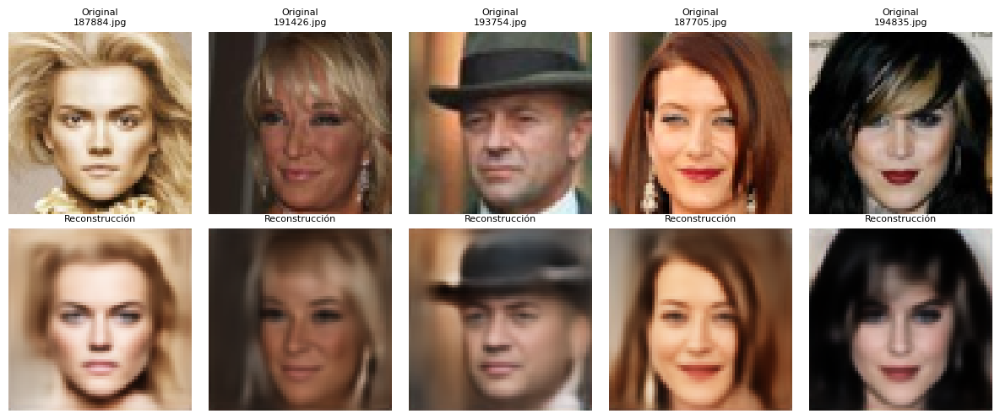

In [11]:
test_indices = sample_rng.choice(len(x_test), size=5, replace=False)
test_reconstructions = autoencoder.predict(x_test[test_indices], verbose=0)
comparison = np.concatenate([x_test[test_indices], test_reconstructions], axis=0)
titles = [f"Original\n{ids_test[i]}" for i in test_indices] + ["Reconstrucción"] * len(test_indices)
show_images(comparison, titles, cols=5, figsize=(12, 5))

Mejor época según val_loss: 30


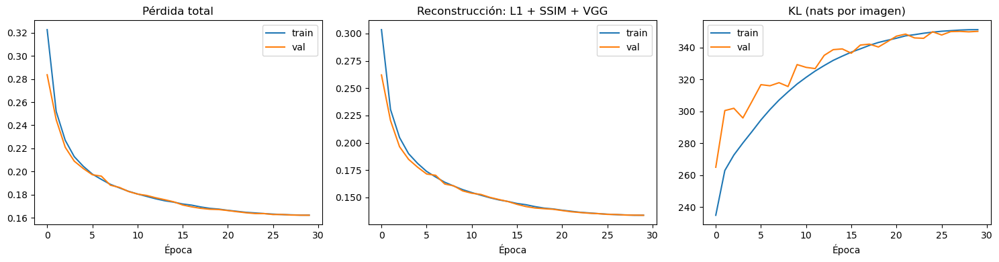

In [12]:
if hasattr(history_ae, "history") and "val_loss" in history_ae.history:
    best_epoch = int(np.argmin(history_ae.history["val_loss"])) + 1
    print(f"Mejor época según val_loss: {best_epoch}")
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, key, title in zip(
        axes,
        ("loss", "recon_loss", "kl_loss"),
        ("Pérdida total", "Reconstrucción: L1 + SSIM + VGG", "KL (nats por imagen)"),
    ):
        ax.plot(history_ae.history[key], label="train")
        ax.plot(history_ae.history[f"val_{key}"], label="val")
        ax.set_title(title)
        ax.set_xlabel("Época")
        ax.legend()
    plt.tight_layout()
    plt.show()

In [13]:
# FID de reconstrucciones y preparación para el FID del morphing
# El FID compara distribuciones de imágenes; por eso se usa un conjunto de test.
FID_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FID_REAL_SAMPLES = min(1000, len(x_test))
FID_BATCH_SIZE = 32


def prepare_images_for_fid(images):
    images = np.asarray(images)
    if images.ndim == 3:
        images = images[..., np.newaxis]
    if images.ndim != 4 or images.shape[-1] not in (1, 3):
        raise ValueError(f"Se esperaban imágenes con forma (N, H, W, 1|3); recibidas {images.shape}")
    if images.dtype != np.uint8:
        images = np.clip(images, 0.0, 1.0)
        images = (images * 255.0).round().astype(np.uint8)
    if images.shape[-1] == 1:
        images = np.repeat(images, 3, axis=-1)
    images = np.transpose(images, (0, 3, 1, 2))
    return torch.from_numpy(np.ascontiguousarray(images))


def calculate_fid(generated_images, real_images, batch_size=FID_BATCH_SIZE):
    generated_images = prepare_images_for_fid(generated_images)
    real_images = prepare_images_for_fid(real_images)
    fid = FrechetInceptionDistance(feature=2048, normalize=False).to(FID_DEVICE)
    with torch.inference_mode():
        for start in range(0, len(real_images), batch_size):
            fid.update(real_images[start:start + batch_size].to(FID_DEVICE), real=True)
        for start in range(0, len(generated_images), batch_size):
            fid.update(generated_images[start:start + batch_size].to(FID_DEVICE), real=False)
    # El cálculo final (raíz de la matriz de covarianzas) se hace en la CPU: si TensorFlow y PyTorch comparten
    # proceso, cuSOLVER de PyTorch puede fallar con CUSOLVER_STATUS_INTERNAL_ERROR. Las características de
    # Inception ya se han calculado en la GPU, así que esto solo mueve unas pocas matrices.
    fid = fid.cpu()
    return float(fid.compute().item())

In [14]:
fid_reconstruction_images = x_test[:FID_REAL_SAMPLES]
fid_reconstruction_reference = x_test[FID_REAL_SAMPLES:2 * FID_REAL_SAMPLES]
reconstructed_test_images = autoencoder.predict(
    fid_reconstruction_images,
    batch_size=FID_BATCH_SIZE,
    verbose=0,
)
reconstruction_fid = calculate_fid(
    reconstructed_test_images,
    fid_reconstruction_reference,
)
print(f"FID de reconstrucciones ({FID_REAL_SAMPLES} imágenes): {reconstruction_fid:.4f}")

FID de reconstrucciones (1000 imágenes): 61.5736


---

## **7. Espacio latente, FID y morphing**

El **Fréchet Inception Distance (FID)** compara dos distribuciones de imágenes a partir de características extraídas por una red Inception; un FID más bajo indica que las imágenes generadas se parecen más, en distribución, a las reales. Mantenemos el protocolo de toda la serie: `1000` reconstrucciones de `test` frente a `1000` imágenes reales distintas de `test`. El FID de reconstrucción de la sección anterior se compara con los `72.94`, `63.65`, `64.40` y `61.17` de la serie de autoencoders, siendo `61.17` (`AE_complex2_VGG`) la base directa.

### **7.1 Diagnóstico del espacio latente**

La razón de ser del VAE es el espacio latente, así que lo inspeccionamos antes de interpolar:

- **KL por dimensión.** Algunas dimensiones pueden quedar «apagadas» (KL ≈ 0 y media constante): el encoder no las usa. Contamos como **activas** las dimensiones cuya media $\mu_j(x)$ varía entre imágenes con varianza mayor que `0.01`. Con `256` dimensiones es habitual que solo una parte se use.
- **Norma de los latentes.** En un espacio gaussiano de dimensión $D$, las muestras del prior tienen norma $\approx \sqrt{D}$. La interpolación lineal entre dos puntos pasa por puntos de norma menor (en el punto medio, $\approx \sqrt{D/2}$), que están en una zona menos probable del prior. Por eso comparamos la interpolación lineal con la **esférica (SLERP)**, que conserva la norma.

### **7.2 Generación desde el prior**

Si el VAE ha regularizado bien el espacio, decodificar $z \sim \mathcal{N}(0, I)$ debería producir caras plausibles, algo que un autoencoder determinista no puede hacer. Lo medimos con el FID de `1000` muestras generadas frente a la misma referencia de `test`. **Este valor no es comparable con el de las reconstrucciones** (generar es una tarea más difícil que reconstruir), pero sí es la medida de lo que el VAE aporta.

**Resultados del diagnóstico del espacio latente** (conjunto `val`):

- **Dimensiones activas: `256` de `256`.** Todas las dimensiones llevan información, no hay dimensiones apagadas. La KL total es de **`350.55` nats por imagen** (`≈ 1.4` nats por dimensión), repartida de forma bastante gradual: de `≈ 3.6` nats en la dimensión más usada a `≈ 0.3` en la que menos.
- **Las medias $\mu$ se parecen al prior.** El histograma de las medias sigue de cerca a una $\mathcal{N}(0, 1)$, algo más concentrado en el centro y con colas más finas, y la norma media de $\mu$ es **`14.92`** frente a `16.00` esperado para una muestra del prior. El espacio latente está razonablemente cerca de una gaussiana estándar, que era el objetivo de la KL.

**Generación desde el prior.** El FID de las `1000` muestras generadas es **`87.43`**, frente a `61.57` de las reconstrucciones (`+25.9`). Esa diferencia es esperable, porque generar es más difícil que reconstruir. Las muestras son claramente **caras plausibles y variadas** (distinto pelo, pose, expresión y sexo), pero borrosas, y algunas tienen artefactos visibles: ojos o bocas deformados (por ejemplo, las muestras `#3` y `#5`). Es un resultado que un autoencoder determinista no puede ofrecer, aunque la calidad es modesta. Para situarlo: una imagen aleatoria da un FID de unos `500` con este protocolo.

I0000 00:00:1793905057.862273   28711 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2481__.1
I0000 00:00:1793905059.319974   30080 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 3124 bytes spill stores, 2868 bytes spill loads

I0000 00:00:1793905061.513769   28707 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2752__.1
I0000 00:00:1793905063.733962   30246 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 18328 bytes spill stores, 17280 bytes spill loads



KL total (val): 350.55 nats por imagen
Dimensiones activas: 256 de 256


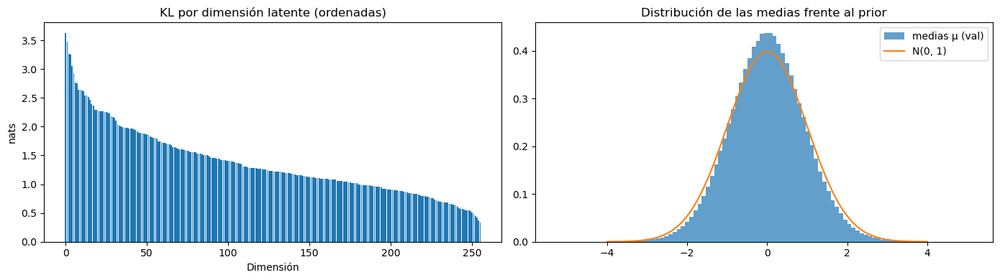

Norma media de μ (val): 14.92 | norma esperada del prior: 16.00


In [15]:
# Estadísticos de la distribución posterior sobre el conjunto de validación.
z_mean_val, z_log_var_val, _ = encoder_vae.predict(x_val, batch_size=256, verbose=0)

kl_per_dim = (-0.5 * (1.0 + z_log_var_val - z_mean_val**2 - np.exp(z_log_var_val))).mean(axis=0)
mean_variance = z_mean_val.var(axis=0)
active_units = int((mean_variance > 0.01).sum())
print(f"KL total (val): {kl_per_dim.sum():.2f} nats por imagen")
print(f"Dimensiones activas: {active_units} de {LATENT_DIM}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(np.arange(LATENT_DIM), np.sort(kl_per_dim)[::-1])
axes[0].set_title("KL por dimensión latente (ordenadas)")
axes[0].set_xlabel("Dimensión")
axes[0].set_ylabel("nats")
axes[1].hist(z_mean_val.ravel(), bins=100, density=True, alpha=0.7, label="medias μ (val)")
grid = np.linspace(-4, 4, 200)
axes[1].plot(grid, np.exp(-0.5 * grid**2) / np.sqrt(2 * np.pi), label="N(0, 1)")
axes[1].set_title("Distribución de las medias frente al prior")
axes[1].legend()
plt.tight_layout()
plt.show()

norms = np.linalg.norm(z_mean_val, axis=1)
print(f"Norma media de μ (val): {norms.mean():.2f} | norma esperada del prior: {np.sqrt(LATENT_DIM):.2f}")

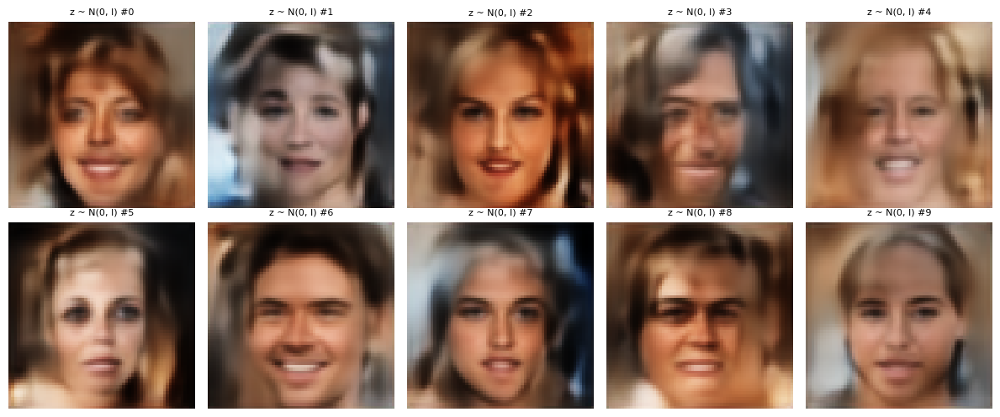

FID de generación desde el prior (1000 imágenes): 87.4286
FID de reconstrucción (1000 imágenes): 61.5736


In [16]:
# Generación desde el prior: z ~ N(0, I). El generador fijo hace reproducible el muestreo.
prior_rng = np.random.default_rng(SEED)
z_prior = prior_rng.standard_normal((FID_REAL_SAMPLES, LATENT_DIM)).astype("float32")
generated_images = decoder_vae.predict(z_prior, batch_size=FID_BATCH_SIZE, verbose=0)

show_images(
    generated_images[:10],
    [f"z ~ N(0, I) #{i}" for i in range(10)],
    cols=5,
    figsize=(12, 5),
)

generation_fid = calculate_fid(generated_images, fid_reconstruction_reference)
print(f"FID de generación desde el prior ({FID_REAL_SAMPLES} imágenes): {generation_fid:.4f}")
print(f"FID de reconstrucción ({FID_REAL_SAMPLES} imágenes): {reconstruction_fid:.4f}")

### **7.3 Morphing: interpolación lineal frente a esférica**

Para el morphing elegimos dos imágenes del conjunto `test`, las codificamos con $\mu(x)$ (sin ruido) y comparamos dos trayectorias entre $z_A$ y $z_B$:

$$\text{Lineal: } z_\alpha = (1-\alpha) z_A + \alpha z_B \qquad\qquad \text{SLERP: } z_\alpha = \frac{\sin((1-\alpha)\Omega)}{\sin \Omega} z_A + \frac{\sin(\alpha \Omega)}{\sin \Omega} z_B$$

donde $\Omega$ es el ángulo entre $z_A$ y $z_B$. La interpolación esférica sigue un arco en lugar de una recta y conserva la norma. Es el experimento A del README. Los extremos se comparan con las imágenes originales para distinguir el efecto de la reconstrucción del efecto de la interpolación.

A: 182638.jpg | B: 182640.jpg
Norma de z: extremos 16.90 y 14.03
Norma en α=0.5: lineal 10.98 | esférica 15.53
Interpolación lineal


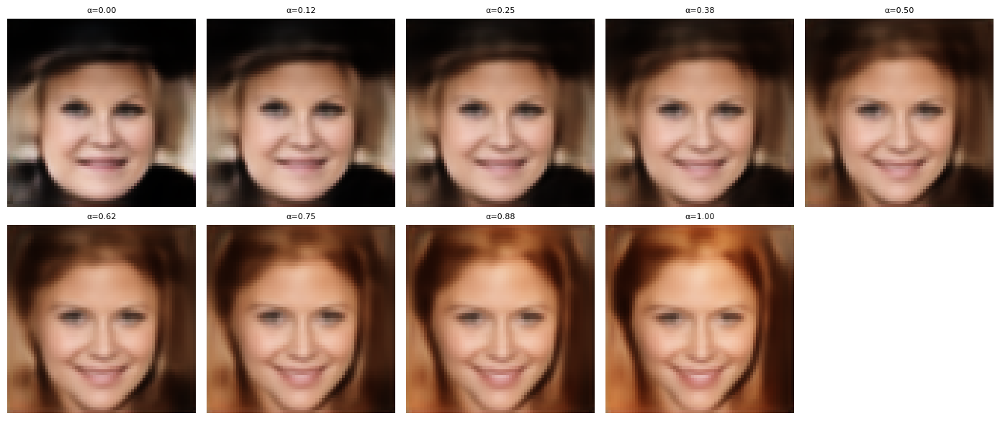

Interpolación esférica (SLERP)


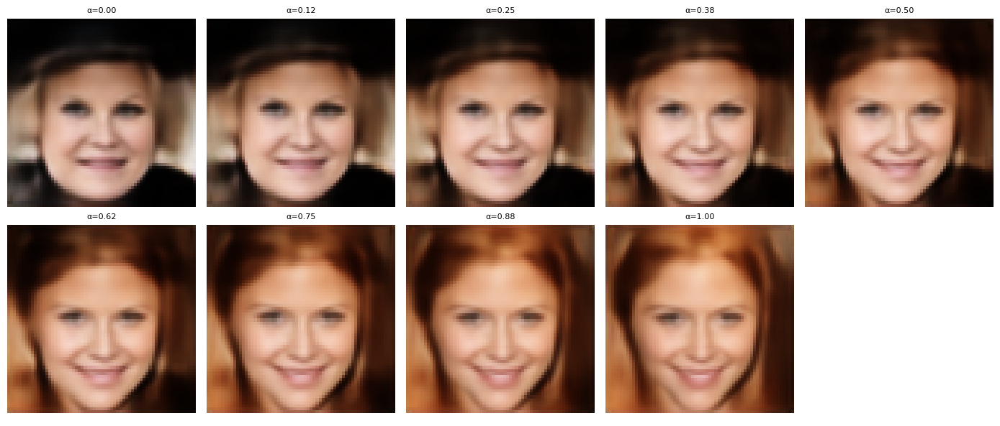

In [17]:
def encode_mean(images):
    # Usamos la media μ(x) como código de la imagen: reconstrucción determinista.
    return encoder_vae.predict(images, verbose=0)[0]


def interpolate_linear(z_a, z_b, alphas):
    return (1.0 - alphas[:, None]) * z_a + alphas[:, None] * z_b


def interpolate_slerp(z_a, z_b, alphas):
    # Ángulo entre los dos vectores; si son casi paralelos, SLERP se reduce a la interpolación lineal.
    cos_omega = np.dot(z_a, z_b) / (np.linalg.norm(z_a) * np.linalg.norm(z_b))
    omega = np.arccos(np.clip(cos_omega, -1.0, 1.0))
    if np.sin(omega) < 1e-6:
        return interpolate_linear(z_a, z_b, alphas)
    weight_a = np.sin((1.0 - alphas) * omega) / np.sin(omega)
    weight_b = np.sin(alphas * omega) / np.sin(omega)
    return weight_a[:, None] * z_a + weight_b[:, None] * z_b


def morph_images(image_a, image_b, steps=9, method="linear"):
    if image_a.shape != image_b.shape:
        raise ValueError(f"Las imágenes deben tener la misma forma; recibidas {image_a.shape} y {image_b.shape}")
    # Codificamos ambos extremos y recorremos la trayectoria elegida entre sus latentes.
    z_a = encode_mean(image_a[None, ...])[0]
    z_b = encode_mean(image_b[None, ...])[0]
    alphas = np.linspace(0.0, 1.0, steps, dtype=np.float32)
    interpolate = {"linear": interpolate_linear, "slerp": interpolate_slerp}[method]
    latent_path = interpolate(z_a, z_b, alphas)
    return alphas, decoder_vae.predict(latent_path, verbose=0), latent_path


morph_a_index, morph_b_index = 0, 1
alphas, morph_sequence, latent_linear = morph_images(x_test[morph_a_index], x_test[morph_b_index], steps=9, method="linear")
_, morph_sequence_slerp, latent_slerp = morph_images(x_test[morph_a_index], x_test[morph_b_index], steps=9, method="slerp")

print(f"A: {ids_test[morph_a_index]} | B: {ids_test[morph_b_index]}")
print(f"Norma de z: extremos {np.linalg.norm(latent_linear[0]):.2f} y {np.linalg.norm(latent_linear[-1]):.2f}")
print(f"Norma en α=0.5: lineal {np.linalg.norm(latent_linear[4]):.2f} | esférica {np.linalg.norm(latent_slerp[4]):.2f}")

print("Interpolación lineal")
show_images(morph_sequence, [f"α={alpha:.2f}" for alpha in alphas], cols=5, figsize=(14, 6))
print("Interpolación esférica (SLERP)")
show_images(morph_sequence_slerp, [f"α={alpha:.2f}" for alpha in alphas], cols=5, figsize=(14, 6))

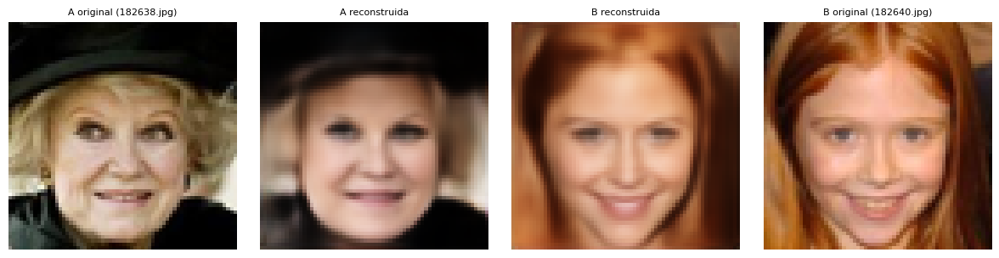

In [18]:
# Comparación de extremos: original frente a reconstrucción usada en la interpolación.
endpoints = np.stack([
    x_test[morph_a_index], morph_sequence[0],
    morph_sequence[-1], x_test[morph_b_index],
])
show_images(
    endpoints,
    [f"A original ({ids_test[morph_a_index]})", "A reconstruida", "B reconstruida", f"B original ({ids_test[morph_b_index]})"],
    cols=4,
    figsize=(12, 3),
)

---

## **8. Secuencia visual y GIF del morphing**

Repetimos la interpolación con muchos valores de $\alpha$ y guardamos los fotogramas como GIF, uno para la interpolación lineal y otro para la esférica. La animación nos permite evaluar visualmente si los rasgos cambian de manera gradual, sin saltos ni *ghosting*, complementando la evaluación numérica del FID.

**Valoración.** La evaluación se basa en las secuencias de `9` pasos de la sección 7.3 (los GIF son la misma interpolación con `80` fotogramas) para el par `182638.jpg` → `182640.jpg`.

- **Suavidad y *ghosting*.** La transición es gradual y **no se aprecia *ghosting***: el sombrero y el pelo claro de `A` se oscurecen y se transforman poco a poco en el pelo pelirrojo de `B`, y la cara intermedia es siempre una cara plausible y no una superposición de dos. Los extremos son reconstrucciones borrosas de las originales (se pierden las arrugas de `A` y la forma exacta de la cara de `B`), así que la transición es suave pero entre dos caras ya degradadas.
- **Lineal frente a esférica.** La teoría se cumple en los números: las normas de los extremos son `16.90` y `14.03`, y en $\alpha = 0.5$ la norma baja a **`10.98`** con la interpolación lineal (un `29 %` menos que la de los extremos, justo el factor $1/\sqrt{2}$ que predice la teoría para vectores casi ortogonales) y se queda en **`15.53`** con SLERP. Sin embargo, **visualmente la diferencia es pequeña** para este par: las dos secuencias son muy parecidas. SLERP produce el punto medio algo más saturado, pero no lo calificamos de mejora clara.

In [19]:
GIF_DIR = PROCESSED_DIR.parent.parent / "gif"
N_FRAMES = 80
FRAME_MS = 50

z_a = encode_mean(x_test[morph_a_index][None, ...])[0]
z_b = encode_mean(x_test[morph_b_index][None, ...])[0]

# Generamos muchos puntos para que la animación resulte visualmente continua.
alphas = np.linspace(0.0, 1.0, N_FRAMES, dtype=np.float32)
gif_sequences = {
    "linear": decoder_vae.predict(interpolate_linear(z_a, z_b, alphas), verbose=0),
    "slerp": decoder_vae.predict(interpolate_slerp(z_a, z_b, alphas), verbose=0),
}

GIF linear guardado en '/home/sanru/Escritorio/7_cuatri/PCD/project/morphing/gif/fusion_vae1_latent256_linear_morphing.gif' | 80 fotogramas


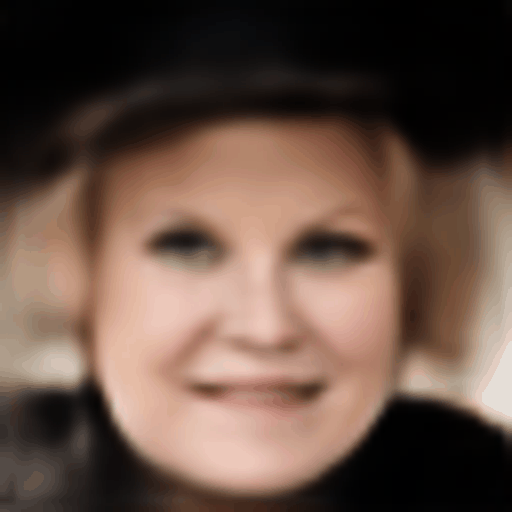

GIF slerp guardado en '/home/sanru/Escritorio/7_cuatri/PCD/project/morphing/gif/fusion_vae1_latent256_slerp_morphing.gif' | 80 fotogramas


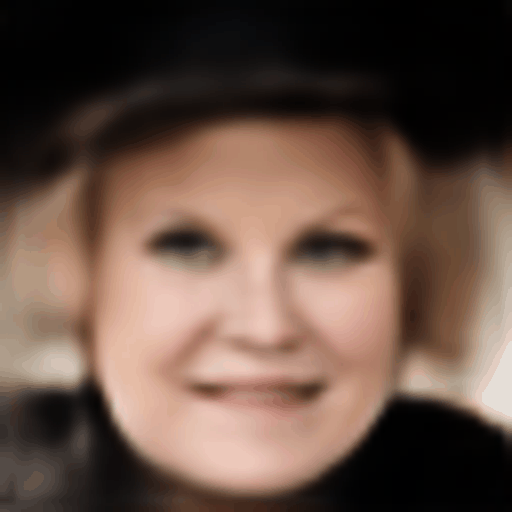

: 

In [ ]:
GIF_PATHS = {
    "linear": GIF_DIR / "fusion_vae1_latent256_linear_morphing.gif",
    "slerp": GIF_DIR / "fusion_vae1_latent256_slerp_morphing.gif",
}

for method, decoded in gif_sequences.items():
    frames = [
        Image.fromarray((np.clip(image, 0, 1) * 255).astype(np.uint8))
        .resize((512, 512), Image.Resampling.BICUBIC)
        for image in decoded
    ]

    gif_path = Path(GIF_PATHS[method]).resolve()
    gif_path.parent.mkdir(parents=True, exist_ok=True)
    if not frames:
        raise RuntimeError("No se generaron fotogramas para el GIF")

    frames[0].save(
        gif_path,
        save_all=True,
        append_images=frames[1:],
        duration=FRAME_MS,
        loop=0,
    )

    print(f"GIF {method} guardado en '{gif_path}' | {len(frames)} fotogramas")
    display(IPyImage(filename=str(gif_path)))

---

## **9. Decisiones de diseño, resultados y siguiente paso**

### **9.1 Decisiones de diseño**

- **Misma arquitectura, pérdida de reconstrucción y entrenamiento que `AE_complex2_VGG`:** convoluciones con `stride=2`, decoder con sobremuestreo bilineal, latente de `256`, pérdida `L1 + SSIM + VGG`, Cosine Decay y `30` épocas. Así, las diferencias se deben al carácter variacional del modelo y no a la red.

- **Dos cabezas (`z_mean`, `z_log_var`) y reparametrización:** es la forma estándar de hacer diferenciable el muestreo. Predecimos $\log\sigma^2$ para no restringir el signo de la salida.

- **Reconstrucción `L1 + (1 − SSIM)` + VGG en lugar de MSE:** mantenemos el objetivo del último AE para aislar el efecto de la KL. La VGG es solo un extractor congelado y no añade parámetros entrenables. Como contrapartida, la pérdida no es un ELBO estricto y `β` no tiene una interpretación probabilística exacta.

- **KL normalizada por el número de valores de la imagen (`12288`):** la reconstrucción es una media por píxel y la KL una suma sobre el latente; la normalización pone ambas en una escala parecida. `β = 1` es un punto de partida sin ajustar.

- **Evaluación con `z_mean`, sin ruido:** las reconstrucciones y el morphing usan la media de la distribución posterior. El ruido solo interviene en el entrenamiento.

- **Interpolación lineal y esférica:** con un prior gaussiano de `256` dimensiones, la línea recta atraviesa puntos de norma menor que la típica, mientras que SLERP la conserva.

- **Latente de `256` y no de `32`:** el README plantea `32` dimensiones y `β = 1` como configuración base del VAE. Aquí mantenemos `256` para que la comparación con la serie de autoencoders sea directa; reducir el latente es una variación natural (experimento B del README).

### **9.2 Resultados**

| Modelo | Latente | Pérdida | FID reconstrucción | FID generación |
| --- | --- | --- | --- | --- |
| `AE_complex1` | 128 | L1 + SSIM | 72.94 | — |
| `AE_complex1_latent` | 256 | L1 + SSIM | 63.65 | — |
| `AE_complex2` (residual) | 256 | L1 + SSIM | 64.40 | — |
| `AE_complex2_VGG` | 256 | L1 + SSIM + VGG | 61.17 | — |
| `VAE_complex1` (`β = 1`) | 256 | L1 + SSIM + VGG + KL | 61.57 | 87.43 |

El FID de reconstrucción del VAE (`61.57`) es **estadísticamente indistinguible** del de `AE_complex2_VGG` (`61.17`): la diferencia de `0.40` puntos (`≈ 0.7 %`) está por debajo del punto de FID que consideramos ruido con `1000` imágenes. Respecto a `AE_complex1_latent` (`63.65`) y `AE_complex2` (`64.40`) baja `2.1` y `2.8` puntos, pero esa comparación no es limpia porque el VAE usa además la pérdida VGG, igual que `AE_complex2_VGG`. En la pérdida de reconstrucción, en cambio, el VAE es un `6 %` peor (`0.1338` frente a `0.1262`). El FID de generación (`87.43`) no tiene equivalente en los autoencoders deterministas, que no pueden muestrear del prior.

### **9.3 Reflexión y siguiente paso**

**Qué hemos comprobado.**

- **El VAE no empeora el FID de reconstrucción** respecto al último autoencoder (`61.57` frente a `61.17`), aunque su pérdida de reconstrucción sea un `6 %` peor y las imágenes salgan algo más borrosas. La pérdida de píxel y el FID miden cosas distintas.
- **El espacio latente es regular:** las `256` dimensiones están activas, no hay *posterior collapse* y las medias se parecen a una $\mathcal{N}(0, 1)$. Esto permite **generar caras nuevas desde el prior** (FID `87.43`), algo que ningún autoencoder de la serie puede hacer, aunque la calidad es modesta (borrosas, con algunos artefactos).
- **El morphing es suave y sin *ghosting*, pero para este par no es mejor que el del autoencoder.** La secuencia de `AE_complex2_VGG` para el mismo par (índices `0` y `1` de `test`) es visualmente casi indistinguible de la del VAE. Esperábamos que el VAE mejorase la interpolación al llenar las zonas vacías del espacio latente (sección 10.2 de `AE_complex2_VGG`), pero en este par esas zonas no producían una degradación visible en el autoencoder, así que no tenemos evidencia de esa mejora.
- **SLERP frente a lineal:** la norma del punto medio confirma la teoría (`10.98` frente a `15.53`), pero la diferencia visual es pequeña.

**Límites de las conclusiones.** Se ha entrenado **un único modelo** (sin repetir con otra semilla), se ha evaluado el morphing con **un solo par** de imágenes y el FID usa `1000` imágenes. Una diferencia de menos de un punto de FID no es interpretable, y un solo par no basta para afirmar que el VAE no mejora el morphing: los pares fáciles pueden no mostrar diferencias que sí aparecerían en pares difíciles (poses muy distintas). Lo honesto es decir que **lo que aporta el VAE en este notebook es la generación y un latente regular, no una mejora medible de la reconstrucción ni, de momento, del morphing**.

Otro límite de este notebook es que `β` se ha fijado en `1` sin explorar, y es el parámetro que más condiciona el compromiso entre reconstrucción y regularidad del espacio latente: no sabemos si un `β` mayor regularizaría más a costa de reconstrucciones peores, ni si uno menor reconstruiría mejor sin perder la regularidad. Los siguientes pasos naturales son:

- **Evaluar el morphing con más pares** (el README propone `20-30`, fáciles y difíciles) y con métricas de continuidad e identidad, para poder comparar de verdad con el autoencoder.
- **Barrer `β`** (por ejemplo `0.5`, `1` y `2`) y observar la relación entre FID de reconstrucción, FID de generación y número de dimensiones activas (experimento C del README).
- **Reducir el latente** (`32` o `64`) para ver si un VAE con un cuello de botella más estricto mantiene un espacio más regular (experimento B).